# K-Means

In [179]:
import pandas as pd
import matplotlib.pyplot as plt
import random
import math
from sklearn.preprocessing import StandardScaler
import numpy as np

### Load Data

In [180]:
df = pd.read_csv("../data/raw/penguins.csv")

display(df.head())
display(df.describe())
print(df.info())

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB
None


### Preprocessing

In [181]:
def check_data(df:pd.DataFrame):
      print("Null Values: ", df.isna().sum())
      print("Dublicated Instances: ", df.duplicated().sum())

      # Check Outliers
      numeric_df = df.select_dtypes(include='number')

      Q1 = numeric_df.quantile(.25)
      Q3 = numeric_df.quantile(.75)

      IQR = Q3-Q1

      lower_bound = Q1 - 1.5 * IQR
      upper_bound = Q3 +1.5 * IQR

      for col in numeric_df:
            outliers = numeric_df[(numeric_df[col] < lower_bound[col]) | (numeric_df[col] > upper_bound[col])]
            print(f"{col}: {len(outliers)} outliers")
            if len(outliers) > 0:
                  print(f"{col}: Max Value = {numeric_df[col].max()} \t Min Value = {numeric_df[col].min()} \t Median Value = {numeric_df[col].median()} \t Q1 Value = {numeric_df[col].quantile(.25)} \t Q3 Value = {numeric_df[col].quantile(.75)}")
check_data(df)

Null Values:  culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64
Dublicated Instances:  1
culmen_length_mm: 0 outliers
culmen_depth_mm: 0 outliers
flipper_length_mm: 2 outliers
flipper_length_mm: Max Value = 5000.0 	 Min Value = -132.0 	 Median Value = 197.0 	 Q1 Value = 190.0 	 Q3 Value = 213.75
body_mass_g: 0 outliers


In [182]:
def fix_data(df):
    df_clean = df.drop_duplicates().copy()
    
    numeric_cols = df_clean.select_dtypes(include='number').columns
    cat_cols = df_clean.select_dtypes(exclude='number').columns
    
    if len(numeric_cols) > 0:
        df_clean[numeric_cols] = df_clean[numeric_cols].fillna(
        df_clean[numeric_cols].median()
    )
    
    if len(cat_cols) > 0:
        df_clean[cat_cols] = df_clean[cat_cols].fillna(
        df_clean[cat_cols].mode().iloc[0]
    )
        
    for col in numeric_cols:
            Q1 = df_clean[col].quantile(0.25)
            Q3 = df_clean[col].quantile(0.75)
            IQR = Q3 - Q1
            
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            
            df_clean[col] = df_clean[col].clip(lower=lower_bound, upper=upper_bound)
    
    scaler = StandardScaler()
    df_clean_scaled = pd.DataFrame(
        scaler.fit_transform(df_clean[numeric_cols]),
        columns=numeric_cols,
        index=df_clean[numeric_cols].index
    )
    
    df_clean_scaled = pd.concat([df_clean_scaled, df_clean[cat_cols]],axis=1)
    return df_clean_scaled

df = fix_data(df)
check_data(df)

Null Values:  culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64
Dublicated Instances:  0
culmen_length_mm: 0 outliers
culmen_depth_mm: 0 outliers
flipper_length_mm: 0 outliers
body_mass_g: 0 outliers


### K-means Implementation

In [ ]:
class KMeans:
      
      def __init__(self,dataset:pd.DataFrame,k=2, exclude_cols=None):
            self.k = k
            exclude_cols = exclude_cols or []
            self.dataset = (
                  dataset
                  .select_dtypes(include='number')
                  .drop(columns=exclude_cols, errors='ignore')
            )
            self.clusters = []
            self.centroids = []
            
      def show(self):
            print(f"K is {self.k}")

      def classInit(self):
            for _ in range(self.k):
                  self.centroids.append([random.uniform(self.dataset[col].min(), self.dataset[col].max()) for col in self.dataset.columns ])

      def __calc_distance(self,p,q):
            if len(p) != len(q):
                  raise ValueError("There are an error: p.length not equal q.length")
            squared_distances = [
                  (x - y) ** 2
                  for x, y in zip(p, q)
            ]

            distance = math.sqrt(sum(squared_distances))

            return distance
      
      def assign_clusters(self):
            self.clusters = [[] for _ in range(self.k)]
            
            for _,row in self.dataset.iterrows():
                  point = row.to_numpy()
                  
                  distances = [
                        self.__calc_distance(point, centroid)
                        for centroid in self.centroids
                  ]

                  nearest_cluster = distances.index(min(distances))
                  self.clusters[nearest_cluster].append(point)
      
      def update_centroids(self):
            new_centroids = []
            
            for i, cluster in enumerate(self.clusters):
                  if len(cluster) == 0:
                        new_centroids.append(self.centroids[i])
                        continue
      
                  clustter_array = np.array(cluster)
                  centroid = clustter_array.mean(axis=0)
                  new_centroids.append(centroid)
            
            self.centroids = new_centroids
                  
      def execute(self, max_iter=100, tol=0.0001):
            self.classInit()
            
            for iteration in range(max_iter):
                  old_centroids = np.array(self.centroids)
                  
                  self.assign_clusters()
                  self.update_centroids()
                  
                  new_centroids = np.array(self.centroids)
                  
                  shifts = np.linalg.norm(
                        new_centroids - old_centroids,
                        axis=1
                  )
                  
                  if np.all(shifts < tol):
                        print(f"Converged at iteration {iteration + 1}")
                        break
            else:
                  print("Maximum iterations reached")
            self.assign_clusters()
      
      def descrip(self):
            for i, cluster in enumerate(self.clusters):
                  print(f"Cluster {i}: {len(cluster)} records")
                  
                  cluster_array = np.array(cluster)
                  plt.scatter(
                        cluster_array[:,0],
                        cluster_array[:, 1],
                        label=f"Cluster {i}",
                        alpha=0.6
                        ),
                  
            centroids = np.array(self.centroids)
            plt.scatter(
            centroids[:, 0],
            centroids[:, 1],
            marker='X',
            s=200,
            edgecolors='black',
            label='Centroids'
            )
                  

            plt.xlabel(self.dataset.columns[0])
            plt.ylabel(self.dataset.columns[1])
            plt.title("K-Means Clustering")
            plt.legend()
            plt.grid(alpha=0.3)

            plt.show()
      
      def scatter(self):
            fig = plt.figure(figsize=(12, 8))
            ax = fig.add_subplot(111, projection='3d')
            
            for i, cluster in enumerate(self.clusters):
                  cluster_array = np.array(cluster)
                  
                  ax.scatter(
                        cluster_array[:, 0],
                        cluster_array[:, 1],
                        cluster_array[:, 2],
                        label=f"Cluster {i}",
                        alpha=0.6
                  )
                  
            centroids = np.array(self.centroids)
            ax.scatter(
                  centroids[:, 0],
                  centroids[:, 1],
                  centroids[:, 2],
                  marker='X',
                  s=250,
                  edgecolors='black',
                  label='Centroids'
            )
            
            ax.set_xlabel(self.dataset.columns[0])
            ax.set_ylabel(self.dataset.columns[1])
            ax.set_zlabel(self.dataset.columns[2])
            
            ax.set_title("K-Means Clustering - 3 Features")
            ax.legend()
            
            plt.show()



Converged at iteration 6
Cluster 0: 124 records
Cluster 1: 87 records
Cluster 2: 132 records


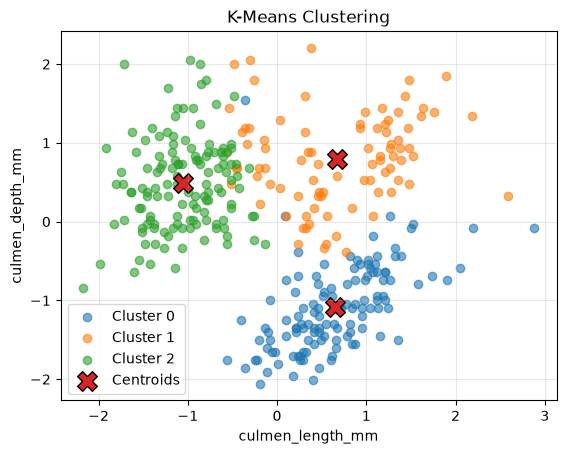

In [188]:
kmeans = KMeans(df,k=3)
kmeans.execute()
kmeans.descrip()

### Note
we can notice that some points classified within cluster 1 and 2 but this points is far away its class. there is because we calculated the distance based on 4 features, but for the sake of simplicity, we only presented 2 dimintions.
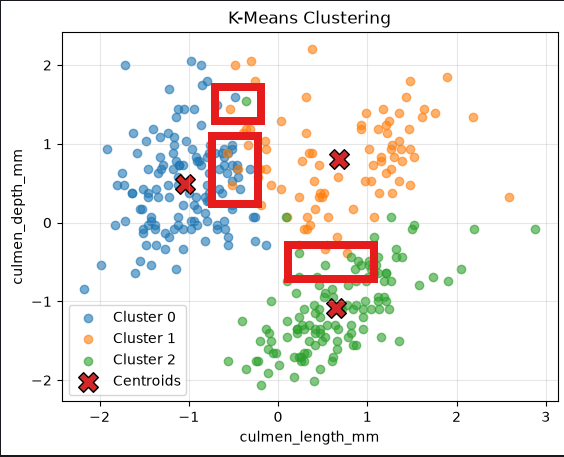

### Instagram Visitors Dataset

Null Values:  User ID                    0
Instagram visit score      0
Spending_rank(0 to 100)    0
dtype: int64
Dublicated Instances:  0
User ID: 0 outliers
Instagram visit score: 0 outliers
Spending_rank(0 to 100): 0 outliers
Converged at iteration 11
Cluster 0: 1535 records
Cluster 1: 1065 records


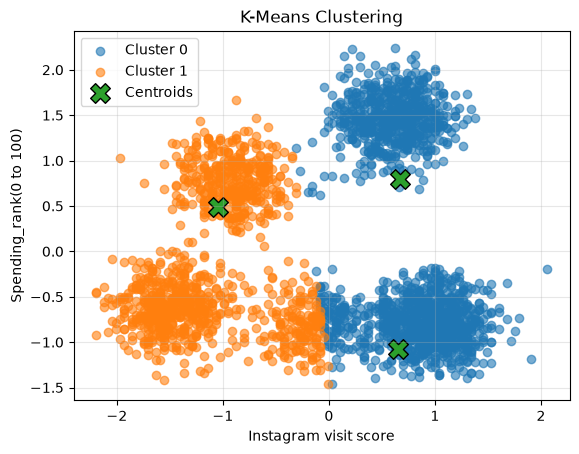

In [189]:
insta_df = pd.read_csv('../data/raw/Instagram visits clustering.csv')

check_data(insta_df)
insta_df = fix_data(insta_df)

insta_kmeans = KMeans(insta_df,k=2,exclude_cols=['User ID'])
insta_kmeans.execute()
insta_kmeans.descrip()